In [1]:
# =============================================================================
# CivicComp Synthetic Dataset — Complete Validation Notebook (v2)
# =============================================================================
import os, re, warnings, itertools
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import wilcoxon, chi2_contingency, spearmanr
from sklearn.metrics import cohen_kappa_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

In [2]:
# =============================================================================
# 0. CONFIGURATION  (single source of truth)
# =============================================================================
SAMPLE_SIZE      = 3000
RANDOM_STATE     = 42
PASS_THRESHOLD   = 8
NEAR_DUP_THRESH = 0.90

ORIGINAL_FILE = "dataset/complaints_hinglish.csv"
PERSON1_FILE  = "dataset/CivicComp_1500_Annotator_1_Simulated.xlsx"
PERSON2_FILE  = "dataset/CivicComp_1500_Annotator_2_Simulated.xlsx"

SAMPLED_XLSX  = f"CivicComp_{SAMPLE_SIZE}_Stratified_Manual_Validation.xlsx"
OUTPUT_DIR    = "CivicComp_Synthetic_Validation_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)
FIG_DIR       = os.path.join(OUTPUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)
OUTPUT_EXCEL  = os.path.join(OUTPUT_DIR, "Complete_Synthetic_Data_Validation_Report.xlsx")

SCORE_COLUMNS = [
    "English_Quality", "Hindi_Quality", "Hinglish_Quality",
    "Semantic_Validity", "Translation_Consistency",
]
LABEL_COLUMNS = [
    "Verified_Primary_Category",
    "Verified_Secondary_Category",
    "Verified_Severity",
]
TEXT_COLUMNS = ["Text_en", "Text_hi", "Text_hinglish"]

In [3]:
# =============================================================================
# 0b. SHARED HELPERS  (defined once, used everywhere)
# =============================================================================
def clean_labels(s: pd.Series) -> pd.Series:
    return s.fillna("").astype(str).str.strip()

def safe_kappa(a, b, weights=None):
    """Cohen's kappa on two aligned label series, tolerant of blanks/singletons."""
    a, b = clean_labels(a), clean_labels(b)
    valid = a.ne("") & b.ne("")
    if valid.sum() < 2:
        return np.nan
    aa, bb = a[valid], b[valid]
    if aa.nunique() < 2 and bb.nunique() < 2:
        return np.nan
    return cohen_kappa_score(aa, bb, weights=weights)

def bootstrap_mean_ci(values, n_boot=5000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v)]
    if v.size == 0:
        return np.nan, np.nan
    means = np.array([rng.choice(v, size=v.size, replace=True).mean() for _ in range(n_boot)])
    return float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))

def savefig(name):
    path = os.path.join(FIG_DIR, f"{name}.png")
    plt.tight_layout()
    plt.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close()
    return path

In [4]:
# =============================================================================
# 1. LOAD & VERIFY DATASET
# =============================================================================
original_df = pd.read_csv(ORIGINAL_FILE)
assert original_df["Sy_No"].is_unique, "Duplicate Sy_No in original dataset"
required = ["Sy_No", "Complaint_Title", *TEXT_COLUMNS,
            "primary_category", "secondary_category", "Severity", "Model_Name"]
missing = [c for c in required if c not in original_df.columns]
if missing:
    raise ValueError(f"Original dataset missing: {missing}")

print("=" * 70)
print("CIVICCOMP SYNTHETIC DATASET — STRATIFIED MANUAL VALIDATION SAMPLING")
print("=" * 70)
print(f"Original shape : {original_df.shape}")
print(f"Missing values :\n{original_df[required].isna().sum()}")

CIVICCOMP SYNTHETIC DATASET — STRATIFIED MANUAL VALIDATION SAMPLING
Original shape : (15000, 9)
Missing values :
Sy_No                 0
Complaint_Title       0
Text_en               0
Text_hi               0
Text_hinglish         0
primary_category      0
secondary_category    0
Severity              0
Model_Name            0
dtype: int64


In [5]:
# =============================================================================
# 2. STRATIFIED PROPORTIONAL SAMPLING (largest-remainder method)
# =============================================================================
strat_cols = ["primary_category", "Severity", "Model_Name"]
strata = (
    original_df[strat_cols].fillna("Unknown").astype(str).agg(" | ".join, axis=1)
)
counts = strata.value_counts()

allocation = counts / len(original_df) * SAMPLE_SIZE
sample_counts = np.floor(allocation).astype(int)
remainder = SAMPLE_SIZE - int(sample_counts.sum())
if remainder > 0:
    for g in (allocation - sample_counts).sort_values(ascending=False).index[:remainder]:
        sample_counts.loc[g] += 1

assert (sample_counts <= counts).all(), "Stratum allocated more rows than it holds"
assert sample_counts.sum() == SAMPLE_SIZE, "Sampling allocation mismatch"

rng_state = RANDOM_STATE
sampled_idx = []
for g, n in sample_counts.items():
    if n == 0:
        continue
    pool = original_df[strata == g]
    sampled_idx.extend(pool.sample(n=int(n), random_state=rng_state).index.tolist())

sample_df = (
    original_df.loc[sampled_idx]
    .sample(frac=1, random_state=rng_state)
    .reset_index(drop=True)
)

assert len(sample_df) == SAMPLE_SIZE
assert sample_df["Sy_No"].is_unique

# Add blank review columns for the human rater
for c in ["Verified_Primary_Category", "Verified_Secondary_Category",
          "Verified_Severity", *SCORE_COLUMNS]:
    sample_df[c] = ""
sample_df["Overall_Status"] = "Not Reviewed"
sample_df["Reviewer_Comments"] = ""

print(f"Sampled records : {len(sample_df)} ({SAMPLE_SIZE/len(original_df)*100:.2f}%)")

Sampled records : 3000 (20.00%)


In [6]:
# =============================================================================
# 3. DISTRIBUTION REPORT (original vs sample)
# =============================================================================
def distribution_report(col):
    o = original_df[col].fillna("Unknown").value_counts().rename("Original_Count")
    s = sample_df[col].fillna("Unknown").value_counts().rename("Sample_Count")
    r = pd.concat([o, s], axis=1).fillna(0).astype(int)
    r["Original_%"] = (r["Original_Count"] / len(original_df) * 100).round(2)
    r["Sample_%"]   = (r["Sample_Count"]   / len(sample_df)     * 100).round(2)
    r["Abs_Diff_%"] = (r["Sample_%"] - r["Original_%"]).abs().round(2)
    return r.reset_index(names="Value")

dist_reports = {c: distribution_report(c)
                for c in ["primary_category", "secondary_category", "Severity", "Model_Name"]}
for c, r in dist_reports.items():
    print(f"\n--- {c} ---\n{r.to_string(index=False)}")


--- primary_category ---
                              Value  Original_Count  Sample_Count  Original_%  Sample_%  Abs_Diff_%
                        Electricity            1875           375        12.5     12.50        0.00
Encroachment & Illegal Construction            1875           378        12.5     12.60        0.10
                Health & Sanitation            1875           377        12.5     12.57        0.07
                      Public Safety            1875           375        12.5     12.50        0.00
              Road & Transportation            1875           372        12.5     12.40        0.10
                   Waste Management            1875           372        12.5     12.40        0.10
                      Water Leakage            1875           374        12.5     12.47        0.03
                             Others            1875           377        12.5     12.57        0.07

--- secondary_category ---
                                Value  Origina

In [7]:
# =============================================================================
# 4. EXPORT SAMPLING WORKBOOK
# =============================================================================
with pd.ExcelWriter(SAMPLED_XLSX, engine="openpyxl") as w:
    sample_df.to_excel(w, "Manual_Validation", index=False)
    for c, r in dist_reports.items():
        r.to_excel(w, f"{c[:25]}_Distribution", index=False)
    pd.DataFrame({
        "Parameter": ["Original Size", "Sample Size", "Sampling %",
                      "Random State", "Stratification Columns", "Method"],
        "Value": [len(original_df), len(sample_df),
                  f"{SAMPLE_SIZE/len(original_df)*100:.2f}%", RANDOM_STATE,
                  ", ".join(strat_cols), "Proportional stratified w/ largest remainder"],
    }).to_excel(w, "Sampling_Summary", index=False)
print(f"\n✅ Sampling workbook written → {SAMPLED_XLSX}")

C:\Users\CH.SC.U4CSE23160\AppData\Local\Temp\ipykernel_6248\426064323.py:5: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  sample_df.to_excel(w, "Manual_Validation", index=False)
C:\Users\CH.SC.U4CSE23160\AppData\Local\Temp\ipykernel_6248\426064323.py:7: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  r.to_excel(w, f"{c[:25]}_Distribution", index=False)
C:\Users\CH.SC.U4CSE23160\AppData\Local\Temp\ipykernel_6248\426064323.py:8: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  pd.DataFrame({



✅ Sampling workbook written → CivicComp_3000_Stratified_Manual_Validation.xlsx


In [8]:
# =============================================================================
# 5. LOAD REVIEWER ANNOTATIONS  (fixed merge)
# =============================================================================
person1 = pd.read_excel(PERSON1_FILE, sheet_name="Manual_Validation")
person2 = pd.read_excel(PERSON2_FILE, sheet_name="Manual_Validation")

for name, p in [("Person 1", person1), ("Person 2", person2)]:
    assert p["Sy_No"].is_unique, f"{name} has duplicate Sy_No"
    miss = [c for c in ["Sy_No", *SCORE_COLUMNS, *LABEL_COLUMNS] if c not in p.columns]
    if miss:
        raise ValueError(f"{name} missing: {miss}")

assert set(person1["Sy_No"]) == set(person2["Sy_No"]), \
    "Reviewer files cover different record IDs"

not_in_orig = set(person1["Sy_No"]) - set(original_df["Sy_No"])
assert not not_in_orig, f"{len(not_in_orig)} reviewer Sy_No not in original"

# ---- per-reviewer frames (only these are used downstream) ----
p1 = person1.set_index("Sy_No").sort_index()
p2 = person2.set_index("Sy_No").sort_index()

# ---- master frame (convenience view only — NOT used by metrics) ----
ORIG_META = ["Complaint_Title", "Text_en", "Text_hi", "Text_hinglish",
             "primary_category", "secondary_category", "Severity", "Model_Name"]
master = (
    original_df.set_index("Sy_No")[ORIG_META]
        .join(p1.add_suffix("__p1"), how="inner")
        .join(p2.add_suffix("__p2"), how="inner")
        .reset_index()
)

print(f"\nmaster: {master.shape} "
      f"(original metadata + {len(p1.columns)} P1 cols + {len(p2.columns)} P2 cols)")
print("Sample columns:", list(master.columns[:6]), "...")

# Quick sanity print — should be zero
print(f"Rows not in both reviewers: "
      f"{(set(original_df['Sy_No']) - set(master['Sy_No'])).__len__()} "
      f"(these are the ~un-sampled rows, expected)")


master: (1500, 45) (original metadata + 18 P1 cols + 18 P2 cols)
Sample columns: ['Sy_No', 'Complaint_Title', 'Text_en', 'Text_hi', 'Text_hinglish', 'primary_category'] ...
Rows not in both reviewers: 13500 (these are the ~un-sampled rows, expected)


In [9]:
# =============================================================================
# 6. DATASET INTEGRITY REPORT
# =============================================================================
integrity = pd.DataFrame([{
    "Column": c,
    "Rows": len(original_df),
    "Missing": int(original_df[c].isna().sum()),
    "Blank": int(original_df[c].astype("string").str.strip().eq("").sum()),
    "Missing_%": round(original_df[c].isna().mean() * 100, 2),
} for c in original_df.columns])

dup_ids = original_df[original_df["Sy_No"].duplicated(keep="first")]
dup_en  = original_df[original_df["Text_en"].fillna("").str.strip()
                      .duplicated(keep="first")]
empty   = original_df[original_df[TEXT_COLUMNS].fillna("").apply(
    lambda r: all(str(v).strip() == "" for v in r), axis=1)]

print("\nDATASET INTEGRITY")
print(integrity.to_string(index=False))
print(f"\nDuplicate IDs               : {len(dup_ids)}")
print(f"Extra duplicate English rows: {len(dup_en)}")
print(f"Completely empty complaints : {len(empty)}")


DATASET INTEGRITY
            Column  Rows  Missing  Blank  Missing_%
             Sy_No 15000        0      0        0.0
   Complaint_Title 15000        0      0        0.0
           Text_en 15000        0      0        0.0
           Text_hi 15000        0      0        0.0
     Text_hinglish 15000        0      0        0.0
  primary_category 15000        0      0        0.0
secondary_category 15000        0      0        0.0
          Severity 15000        0      0        0.0
        Model_Name 15000        0      0        0.0

Duplicate IDs               : 0
Extra duplicate English rows: 133
Completely empty complaints : 0


In [10]:
# =============================================================================
# 7. INTER-ANNOTATOR AGREEMENT  (numeric + categorical)
# =============================================================================
agree_rows = []
for col in SCORE_COLUMNS:
    a = pd.to_numeric(p1[col], errors="coerce")
    b = pd.to_numeric(p2[col], errors="coerce")
    valid = a.notna() & b.notna()
    aa, bb = a[valid], b[valid]
    agree_rows.append({
        "Dimension": col, "Type": "Ordinal",
        "N": int(valid.sum()),
        "P1_Mean": aa.mean(), "P2_Mean": bb.mean(),
        "P1_SD":   aa.std(),  "P2_SD":   bb.std(),
        "Exact_Agreement": (aa == bb).mean(),
        "Kappa":  safe_kappa(aa, bb),
        "Kappa_Q": safe_kappa(aa, bb, weights="quadratic"),
    })
for col in LABEL_COLUMNS:
    a, b = clean_labels(p1[col]), clean_labels(p2[col])
    agree_rows.append({
        "Dimension": col, "Type": "Categorical", "N": len(a),
        "P1_Mean": np.nan, "P2_Mean": np.nan, "P1_SD": np.nan, "P2_SD": np.nan,
        "Exact_Agreement": (a == b).mean(),
        "Kappa": safe_kappa(a, b),
        "Kappa_Q": np.nan,
    })
agreement_report = pd.DataFrame(agree_rows)
print("\nINTER-ANNOTATOR AGREEMENT")
print(agreement_report.to_string(index=False))


INTER-ANNOTATOR AGREEMENT
                  Dimension        Type    N  P1_Mean  P2_Mean    P1_SD    P2_SD  Exact_Agreement    Kappa  Kappa_Q
            English_Quality     Ordinal 1499 9.078719 9.008672 0.640589 0.643799         0.939960 0.000000 0.822234
              Hindi_Quality     Ordinal 1500 9.000000 8.994000 0.637917 0.641539         0.974667 0.955071 0.965600
           Hinglish_Quality     Ordinal 1500 8.978667 8.997333 0.659167 0.648285         0.973333 0.952869 0.971725
          Semantic_Validity     Ordinal 1500 8.978000 8.980667 0.780975 0.780191         0.989333 0.983710 0.992287
    Translation_Consistency     Ordinal 1500 8.768000 8.768000 0.942391 0.949444         0.990000 0.984862 0.981410
  Verified_Primary_Category Categorical 1500      NaN      NaN      NaN      NaN         1.000000 1.000000      NaN
Verified_Secondary_Category Categorical 1500      NaN      NaN      NaN      NaN         1.000000 1.000000      NaN
          Verified_Severity Categorical 1500 

In [11]:
# =============================================================================
# 9. HUMAN QUALITY ASSESSMENT (per reviewer, per dimension)
# =============================================================================
quality_rows = []
for rname, rdf in [("Person 1", p1), ("Person 2", p2)]:
    for col in SCORE_COLUMNS:
        s = pd.to_numeric(rdf[col], errors="coerce").dropna()
        quality_rows.append({
            "Reviewer": rname, "Dimension": col, "N": len(s),
            "Mean": s.mean(), "SD": s.std(), "Median": s.median(),
            "Min": s.min(), "Max": s.max(),
            "%>=8": (s.ge(PASS_THRESHOLD).mean() * 100),
            "%<6":  (s.lt(6).mean() * 100),
        })
quality_report = pd.DataFrame(quality_rows)
print("\nHUMAN QUALITY ASSESSMENT")
print(quality_report.to_string(index=False))

# Combined score for downstream use
for df in (p1, p2):
    numeric = df[SCORE_COLUMNS].apply(pd.to_numeric, errors="coerce")
    df["Average_Quality_Score"] = numeric.mean(axis=1)
    df["Total_Quality_Score"]   = numeric.sum(axis=1, min_count=len(SCORE_COLUMNS))


HUMAN QUALITY ASSESSMENT
Reviewer               Dimension    N     Mean       SD  Median  Min  Max       %>=8  %<6
Person 1         English_Quality 1499 9.078719 0.640589     9.0  8.0 10.0 100.000000  0.0
Person 1           Hindi_Quality 1500 9.000000 0.637917     9.0  7.0 10.0  99.866667  0.0
Person 1        Hinglish_Quality 1500 8.978667 0.659167     9.0  7.0 10.0  98.933333  0.0
Person 1       Semantic_Validity 1500 8.978000 0.780975     9.0  7.0 10.0  97.800000  0.0
Person 1 Translation_Consistency 1500 8.768000 0.942391     9.0  6.0 10.0  96.200000  0.0
Person 2         English_Quality 1500 9.008000 0.644111     9.0  7.0 10.0  99.933333  0.0
Person 2           Hindi_Quality 1500 8.994000 0.641539     9.0  7.0 10.0  99.800000  0.0
Person 2        Hinglish_Quality 1500 8.997333 0.648285     9.0  7.0 10.0  99.466667  0.0
Person 2       Semantic_Validity 1500 8.980667 0.780191     9.0  7.0 10.0  97.800000  0.0
Person 2 Translation_Consistency 1500 8.768000 0.949444     9.0  6.0 10.0 

In [12]:
# =============================================================================
# 10. LANGUAGE-WISE QUALITY
# =============================================================================
lang_rows = []
for rname, rdf in [("Person 1", p1), ("Person 2", p2)]:
    for lang, col in {"English": "English_Quality",
                      "Hindi": "Hindi_Quality",
                      "Hinglish": "Hinglish_Quality"}.items():
        s = pd.to_numeric(rdf[col], errors="coerce").dropna()
        lang_rows.append({
            "Reviewer": rname, "Language": lang,
            "Mean": s.mean(), "SD": s.std(), "Median": s.median(),
            "%>=8": s.ge(PASS_THRESHOLD).mean() * 100,
            "%<6":  s.lt(6).mean() * 100,
        })
language_report = pd.DataFrame(lang_rows)
print("\nLANGUAGE-WISE QUALITY")
print(language_report.to_string(index=False))


LANGUAGE-WISE QUALITY
Reviewer Language     Mean       SD  Median       %>=8  %<6
Person 1  English 9.078719 0.640589     9.0 100.000000  0.0
Person 1    Hindi 9.000000 0.637917     9.0  99.866667  0.0
Person 1 Hinglish 8.978667 0.659167     9.0  98.933333  0.0
Person 2  English 9.008000 0.644111     9.0  99.933333  0.0
Person 2    Hindi 8.994000 0.641539     9.0  99.800000  0.0
Person 2 Hinglish 8.997333 0.648285     9.0  99.466667  0.0


In [13]:
# =============================================================================
# 11. LABEL CORRECTNESS (original vs verified)
# =============================================================================
label_map = {
    "primary_category":   "Verified_Primary_Category",
    "secondary_category": "Verified_Secondary_Category",
    "Severity":           "Verified_Severity",
}
label_rows, disagreement_frames = [], []
for rname, rdf in [("Person 1", p1), ("Person 2", p2)]:
    for orig, ver in label_map.items():
        o = clean_labels(rdf[orig])
        v = clean_labels(rdf[ver])
        valid = o.ne("") & v.ne("")
        changed = (o[valid] != v[valid])
        label_rows.append({
            "Reviewer": rname, "Label": orig,
            "Checked": int(valid.sum()),
            "Changed": int(changed.sum()),
            "Unchanged": int((~changed).sum()),
            "Correction_%": changed.mean() * 100 if valid.sum() else np.nan,
        })
label_report = pd.DataFrame(label_rows)
print("\nLABEL CORRECTION REPORT")
print(label_report.to_string(index=False))

# Disagreements between reviewers (for adjudication)
for col in SCORE_COLUMNS + LABEL_COLUMNS:
    a = clean_labels(p1[col]); b = clean_labels(p2[col])
    mask = a != b
    if mask.any():
        temp = pd.DataFrame({
            "Sy_No": p1.index[mask],
            "Dimension": col,
            "Person1_Value": a[mask].values,
            "Person2_Value": b[mask].values,
        })
        disagreement_frames.append(temp)
disagreement_report = (pd.concat(disagreement_frames, ignore_index=True)
                       if disagreement_frames else pd.DataFrame(
                           columns=["Sy_No", "Dimension", "Person1_Value", "Person2_Value"]))
print(f"\nTotal reviewer disagreement entries: {len(disagreement_report)}")


LABEL CORRECTION REPORT
Reviewer              Label  Checked  Changed  Unchanged  Correction_%
Person 1   primary_category     1500       91       1409      6.066667
Person 1 secondary_category     1500        4       1496      0.266667
Person 1           Severity     1500      208       1292     13.866667
Person 2   primary_category     1500       91       1409      6.066667
Person 2 secondary_category     1500        4       1496      0.266667
Person 2           Severity     1500      201       1299     13.400000

Total reviewer disagreement entries: 1624


In [14]:
# =============================================================================
# 12. LLM-WISE QUALITY
# =============================================================================
llm_rows = []
for rname, rdf in [("Person 1", p1), ("Person 2", p2)]:
    tmp = rdf.copy()
    for c in SCORE_COLUMNS:
        tmp[c] = pd.to_numeric(tmp[c], errors="coerce")
    for model, grp in tmp.groupby("Model_Name", dropna=False):
        for c in SCORE_COLUMNS:
            s = grp[c].dropna()
            lo, hi = bootstrap_mean_ci(s.values, n_boot=2000)
            llm_rows.append({
                "Reviewer": rname, "LLM": model, "Dimension": c,
                "N": len(grp), "Mean": s.mean(), "SD": s.std(),
                "CI_Low": lo, "CI_High": hi,
            })
llm_report = pd.DataFrame(llm_rows)
print("\nLLM-WISE QUALITY")
print(llm_report.groupby(["Reviewer", "LLM"])[["Mean", "SD"]].mean().to_string())


LLM-WISE QUALITY
                              Mean        SD
Reviewer LLM                                
Person 1 Claude-Sonnet 5  8.977083  0.739438
         DeepSeek         8.927362  0.720959
         GPT-5.5          8.957456  0.728577
         Gemini           8.985185  0.755607
         Qwen3.7          8.959722  0.702662
Person 2 Claude-Sonnet 5  8.969792  0.739118
         DeepSeek         8.919333  0.724755
         GPT-5.5          8.940351  0.727443
         Gemini           8.974074  0.755650
         Qwen3.7          8.951389  0.703720


In [15]:
# =============================================================================
# 13. CATEGORY-WISE / SEVERITY-WISE QUALITY
# =============================================================================
cat_rows, sev_rows = [], []
for rname, rdf in [("Person 1", p1), ("Person 2", p2)]:
    tmp = rdf.copy()
    for c in SCORE_COLUMNS:
        tmp[c] = pd.to_numeric(tmp[c], errors="coerce")
    for cat, grp in tmp.groupby("primary_category", dropna=False):
        cat_rows.append({
            "Reviewer": rname, "Category": cat, "N": len(grp),
            "Avg_Quality": grp[SCORE_COLUMNS].mean().mean(),
            "English": grp["English_Quality"].mean(),
            "Hindi": grp["Hindi_Quality"].mean(),
            "Hinglish": grp["Hinglish_Quality"].mean(),
            "Semantic": grp["Semantic_Validity"].mean(),
            "Translation": grp["Translation_Consistency"].mean(),
        })
    for sev, grp in tmp.groupby("Severity", dropna=False):
        sev_rows.append({
            "Reviewer": rname, "Severity": sev, "N": len(grp),
            "Avg_Quality": grp[SCORE_COLUMNS].mean().mean(),
            "Semantic": grp["Semantic_Validity"].mean(),
            "Translation": grp["Translation_Consistency"].mean(),
        })
category_report = pd.DataFrame(cat_rows)
severity_report = pd.DataFrame(sev_rows)
print("\nCATEGORY-WISE QUALITY (Person 1 only shown)")
print(category_report[category_report.Reviewer == "Person 1"].to_string(index=False))


CATEGORY-WISE QUALITY (Person 1 only shown)
Reviewer                            Category   N  Avg_Quality  English    Hindi  Hinglish  Semantic  Translation
Person 1                         Electricity 189     8.975661 9.037037 8.941799  9.010582  9.084656     8.804233
Person 1 Encroachment & Illegal Construction 187     8.966845 9.112299 9.026738  8.914439  8.941176     8.839572
Person 1                 Health & Sanitation 187     8.968984 9.053476 9.085561  8.919786  9.016043     8.770053
Person 1                              Others 186     8.993548 9.145161 8.994624  9.026882  8.930108     8.870968
Person 1                       Public Safety 187     8.963636 9.133690 8.983957  9.016043  8.941176     8.743316
Person 1               Road & Transportation 189     9.000000 9.111111 8.973545  9.074074  9.068783     8.772487
Person 1                    Waste Management 188     8.974468 9.069149 9.079787  8.989362  8.946809     8.787234
Person 1                       Water Leakage 187   

In [16]:
# =============================================================================
# 14. STATISTICAL COMPARISON (Person 1 vs Person 2)
# =============================================================================
stat_rows = []
for col in SCORE_COLUMNS:
    a = pd.to_numeric(p1[col], errors="coerce")
    b = pd.to_numeric(p2[col], errors="coerce")
    valid = a.notna() & b.notna()
    aa, bb = a[valid], b[valid]
    diff = aa - bb
    lo, hi = bootstrap_mean_ci(diff.values)
    if len(diff) and not np.allclose(diff, 0):
        W, p = wilcoxon(aa, bb, alternative="two-sided")
    else:
        W, p = 0.0, 1.0
    stat_rows.append({
        "Dimension": col, "P1_Mean": aa.mean(), "P2_Mean": bb.mean(),
        "Mean_Diff": diff.mean(),
        "Diff_CI_Low": lo, "Diff_CI_High": hi,
        "Wilcoxon_W": W, "p_value": p,
        "Significant(p<0.05)": p < 0.05,
    })
statistics_report = pd.DataFrame(stat_rows)
print("\nSTATISTICAL COMPARISON")
print(statistics_report.to_string(index=False))


STATISTICAL COMPARISON
              Dimension  P1_Mean  P2_Mean  Mean_Diff  Diff_CI_Low  Diff_CI_High  Wilcoxon_W      p_value  Significant(p<0.05)
        English_Quality 9.078719 9.008672   0.070047     0.055370      0.085390        37.0 3.715534e-18                 True
          Hindi_Quality 9.000000 8.994000   0.006000    -0.003333      0.016000       291.0 2.089934e-01                False
       Hinglish_Quality 8.978667 8.997333  -0.018667    -0.031333     -0.007333       187.5 1.816146e-03                 True
      Semantic_Validity 8.978000 8.980667  -0.002667    -0.010000      0.004000        53.5 4.296064e-01                False
Translation_Consistency 8.768000 8.768000   0.000000    -0.006667      0.006667        57.0 8.536505e-01                False


In [17]:
# =============================================================================
# 15. EXACT + NEAR DUPLICATE DETECTION
# =============================================================================
exact_rows = []
for col in TEXT_COLUMNS:
    norm = (original_df[col].fillna("").astype(str)
            .str.lower().str.strip().str.replace(r"\s+", " ", regex=True))
    dup_mask = norm.duplicated(keep="first")
    exact_rows.append({
        "Language": col,
        "Extra_Duplicate_Rows": int(dup_mask.sum()),
        "Unique_Texts": int(norm.nunique()),
        "Duplicate_%": round(dup_mask.mean() * 100, 2),
    })
    original_df.loc[dup_mask].to_csv(
        os.path.join(OUTPUT_DIR, f"Exact_Duplicates_{col}.csv"), index=False)
exact_duplicate_report = pd.DataFrame(exact_rows)
print("\nEXACT DUPLICATE REPORT")
print(exact_duplicate_report.to_string(index=False))

# Near duplicates (English, TF-IDF cosine)
texts = original_df["Text_en"].fillna("").astype(str).str.lower().str.strip()
tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2),
                       max_features=30000).fit_transform(texts)
nn = NearestNeighbors(n_neighbors=2, metric="cosine", algorithm="brute",
                     n_jobs=-1).fit(tfidf)
dist, idx = nn.kneighbors(tfidf)
near_pairs = []
for i in range(tfidf.shape[0]):
    j = idx[i, 1]
    sim = 1 - dist[i, 1]
    if i < j and sim >= NEAR_DUP_THRESH:
        near_pairs.append({
            "Sy_No_1": original_df.iloc[i]["Sy_No"],
            "Sy_No_2": original_df.iloc[j]["Sy_No"],
            "Text_1": texts.iloc[i], "Text_2": texts.iloc[j],
            "Similarity": sim,
        })
near_duplicate_report = pd.DataFrame(
    near_pairs,
    columns=["Sy_No_1", "Sy_No_2", "Text_1", "Text_2", "Similarity"])
near_duplicate_report.to_csv(
    os.path.join(OUTPUT_DIR, "Near_Duplicate_Complaints.csv"), index=False)
print(f"\nNear-duplicate pairs (sim ≥ {NEAR_DUP_THRESH}): {len(near_duplicate_report)}")


EXACT DUPLICATE REPORT
     Language  Extra_Duplicate_Rows  Unique_Texts  Duplicate_%
      Text_en                   133         14867         0.89
      Text_hi                   132         14868         0.88
Text_hinglish                   110         14890         0.73

Near-duplicate pairs (sim ≥ 0.9): 160


In [18]:
# =============================================================================
# 16. SYNTHETIC-SPECIFIC VALIDATION (new)
# =============================================================================
print("\n" + "=" * 70)
print("SYNTHETIC-SPECIFIC VALIDATION")
print("=" * 70)

# 16a. Lexical diversity
diversity_rows = []
for col in TEXT_COLUMNS:
    tokens = (original_df[col].fillna("").astype(str)
              .str.lower().str.replace(r"[^\w\s]", "", regex=True)
              .str.split().explode().dropna())
    n_tok, n_types = len(tokens), tokens.nunique()
    diversity_rows.append({
        "Language": col,
        "Total_Tokens": n_tok,
        "Unique_Types": n_types,
        "Type_Token_Ratio": round(n_types / n_tok, 4) if n_tok else np.nan,
        "Avg_Tokens_per_Record": round(n_tok / len(original_df), 2),
    })
diversity_report = pd.DataFrame(diversity_rows)
print("\nLEXICAL DIVERSITY")
print(diversity_report.to_string(index=False))

# 16b. Template-leakage: strip digits/punct, cluster identical skeletons
def skeletonize(s: str) -> str:
    s = re.sub(r"\d+", "<NUM>", s.lower())
    s = re.sub(r"[^\w\s<>]", "", s)
    return re.sub(r"\s+", " ", s).strip()

template_rows = []
for col in TEXT_COLUMNS:
    skels = original_df[col].fillna("").astype(str).map(skeletonize)
    counts = skels.value_counts()
    template_rows.append({
        "Language": col,
        "Unique_Skeletons": int(skels.nunique()),
        "Skeleton_per_Record": round(skels.nunique() / len(original_df), 4),
        "Top_Skeleton_Share_%": round(counts.iloc[0] / len(original_df) * 100, 2),
        "Skeletons_Used_10+_times": int((counts >= 10).sum()),
    })
template_report = pd.DataFrame(template_rows)
print("\nTEMPLATE LEAKAGE")
print(template_report.to_string(index=False))

# 16c. Per-LLM label consistency (chi-square on primary × model)
pivot = pd.crosstab(original_df["primary_category"], original_df["Model_Name"])
if pivot.shape[0] > 1 and pivot.shape[1] > 1:
    chi2, p, dof, _ = chi2_contingency(pivot)
    print(f"\nChi-square (primary_category × Model_Name): "
          f"χ²={chi2:.1f}, dof={dof}, p={p:.4g}")

# 16d. Severity vs. text length
len_stats = (
    original_df.assign(text_len=original_df["Text_en"].fillna("").str.len())
    .groupby("Severity")["text_len"].agg(["count", "mean", "std", "median"])
    .round(1)
)
print("\nSEVERITY vs TEXT LENGTH")
print(len_stats.to_string())

# 16e. Translation length ratios
ratio_df = pd.DataFrame({
    "hi/en":   original_df["Text_hi"].fillna("").str.len()    /
               original_df["Text_en"].fillna("").str.len().replace(0, np.nan),
    "hing/en": original_df["Text_hinglish"].fillna("").str.len() /
               original_df["Text_en"].fillna("").str.len().replace(0, np.nan),
})
ratio_stats = ratio_df.describe().round(3)
print("\nTRANSLATION LENGTH RATIOS")
print(ratio_stats.to_string())

# 16f. Cross-language token overlap (Hinglish should overlap both)
def tokens_of(s):
    return set(re.findall(r"\w+", str(s).lower()))
en_vocab  = set().union(*original_df["Text_en"].dropna().map(tokens_of))
hi_vocab  = set().union(*original_df["Text_hi"].dropna().map(tokens_of))
hin_vocab = set().union(*original_df["Text_hinglish"].dropna().map(tokens_of))
overlap_table = pd.DataFrame([
    {"Pair": "English ∩ Hinglish",
     "Jaccard": len(en_vocab & hin_vocab) / len(en_vocab | hin_vocab)},
    {"Pair": "Hindi ∩ Hinglish",
     "Jaccard": len(hi_vocab & hin_vocab) / len(hi_vocab | hin_vocab)},
    {"Pair": "English ∩ Hindi",
     "Jaccard": len(en_vocab & hi_vocab) / len(en_vocab | hi_vocab)},
]).round(4)
print("\nCROSS-LANGUAGE VOCAB OVERLAP (Jaccard)")
print(overlap_table.to_string(index=False))


SYNTHETIC-SPECIFIC VALIDATION

LEXICAL DIVERSITY
     Language  Total_Tokens  Unique_Types  Type_Token_Ratio  Avg_Tokens_per_Record
      Text_en        461676         10684            0.0231                  30.78
      Text_hi        599216          5974            0.0100                  39.95
Text_hinglish        542313         33410            0.0616                  36.15

TEMPLATE LEAKAGE
     Language  Unique_Skeletons  Skeleton_per_Record  Top_Skeleton_Share_%  Skeletons_Used_10+_times
      Text_en             14867               0.9911                  0.02                         0
      Text_hi             14868               0.9912                  0.02                         0
Text_hinglish             14890               0.9927                  0.18                         5

Chi-square (primary_category × Model_Name): χ²=0.8, dof=28, p=1

SEVERITY vs TEXT LENGTH
          count   mean   std  median
Severity                            
High       5031  222.4  46.5   2


Generating figures…


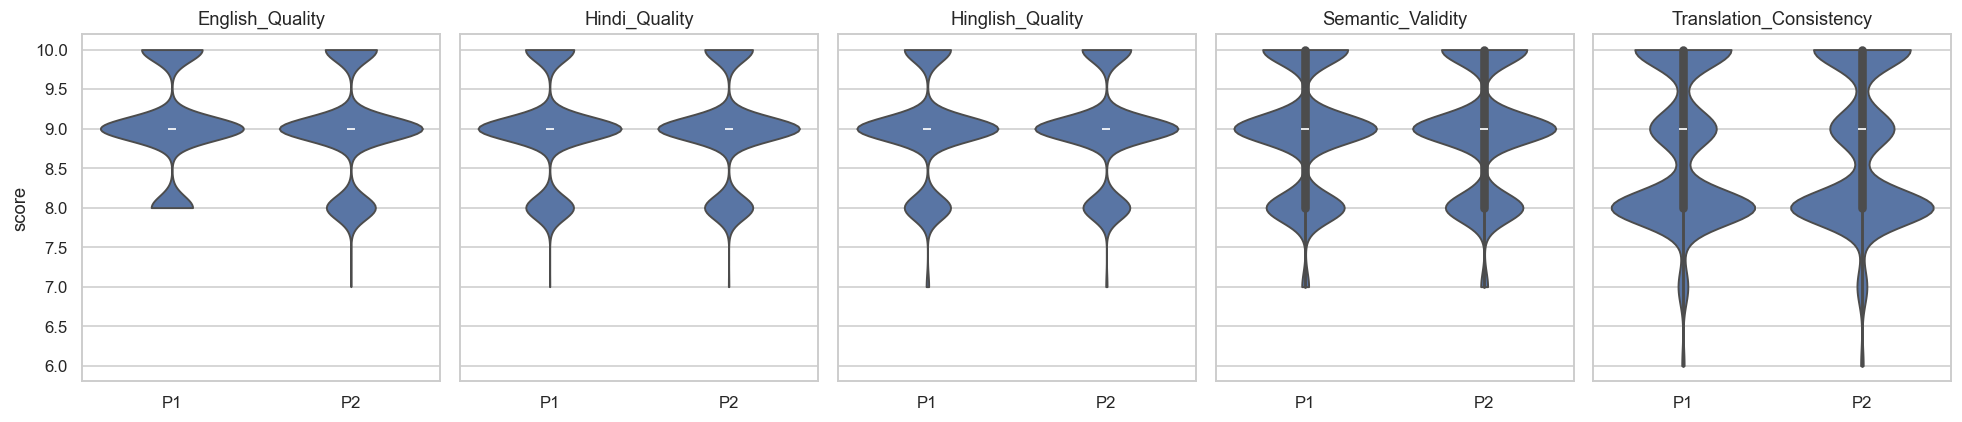

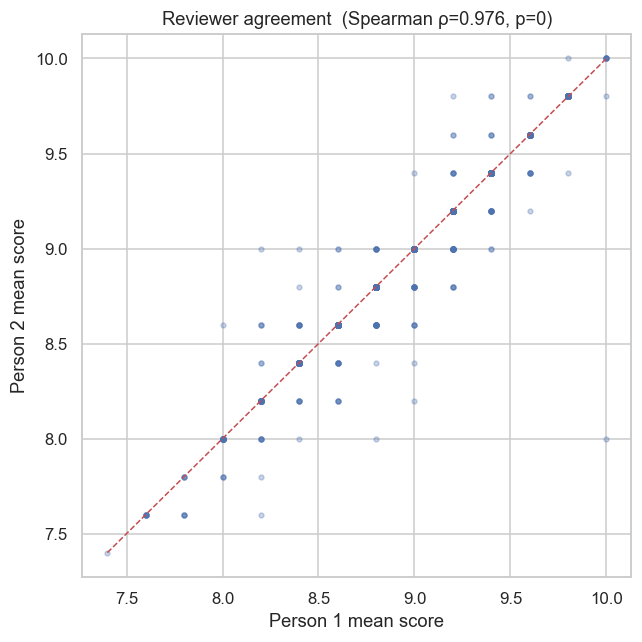

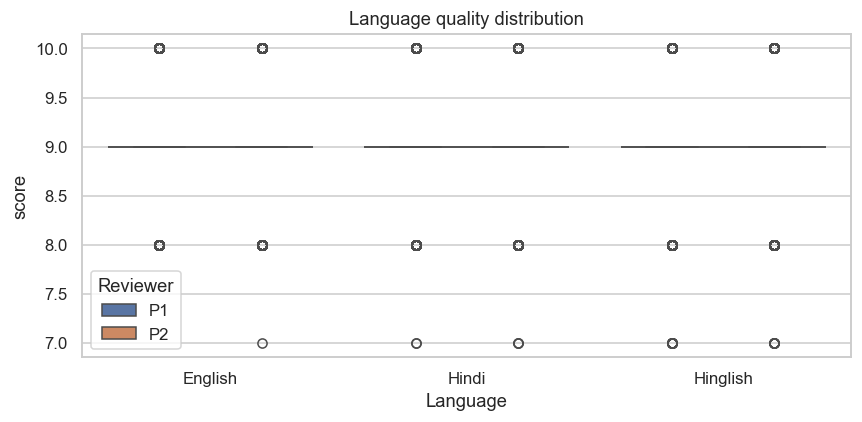

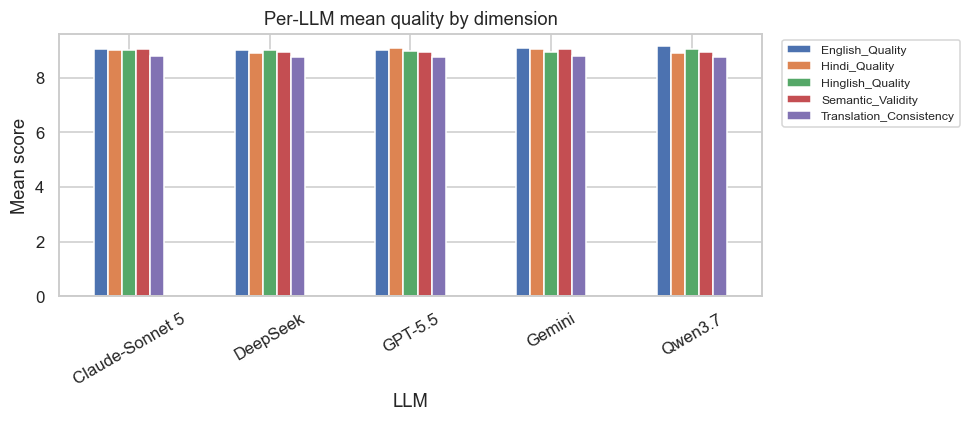

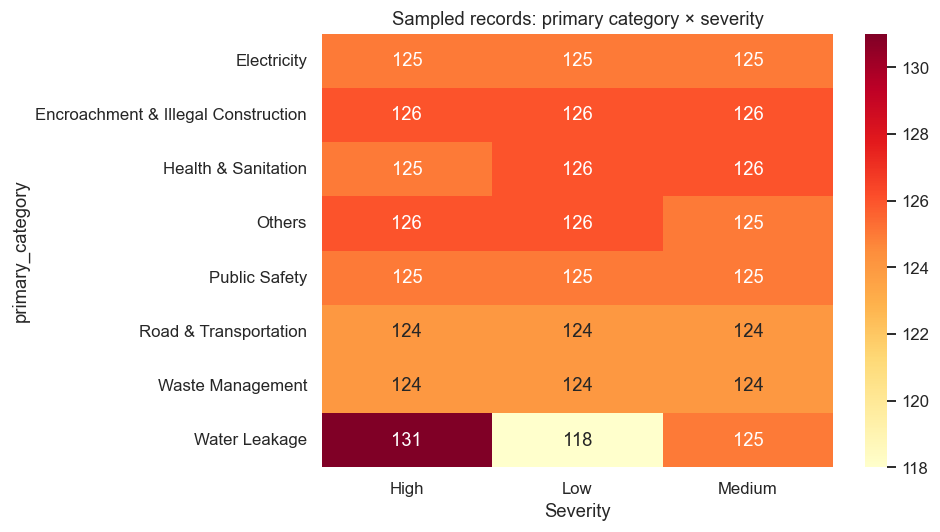

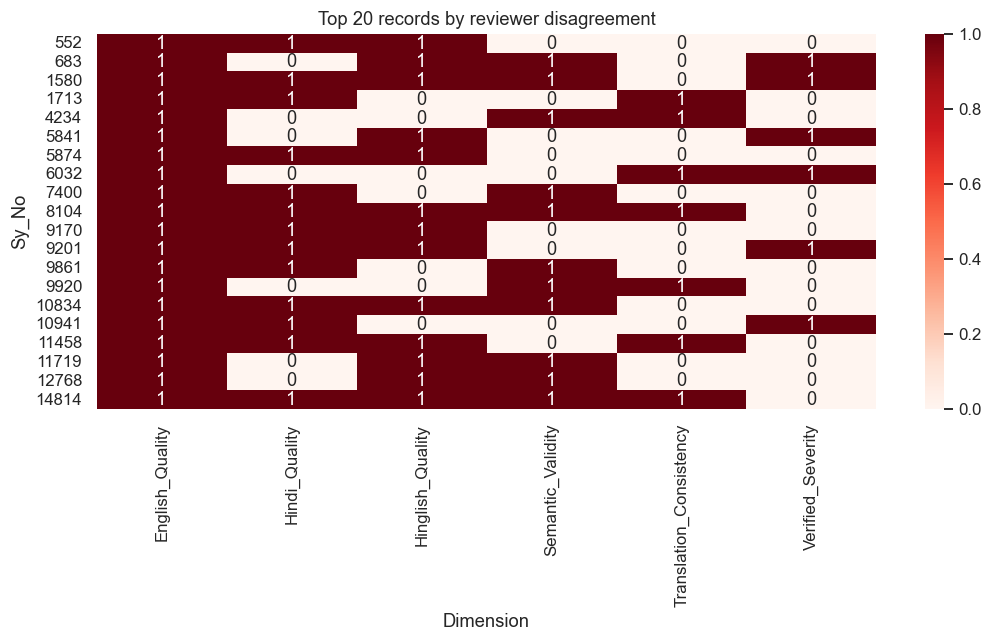

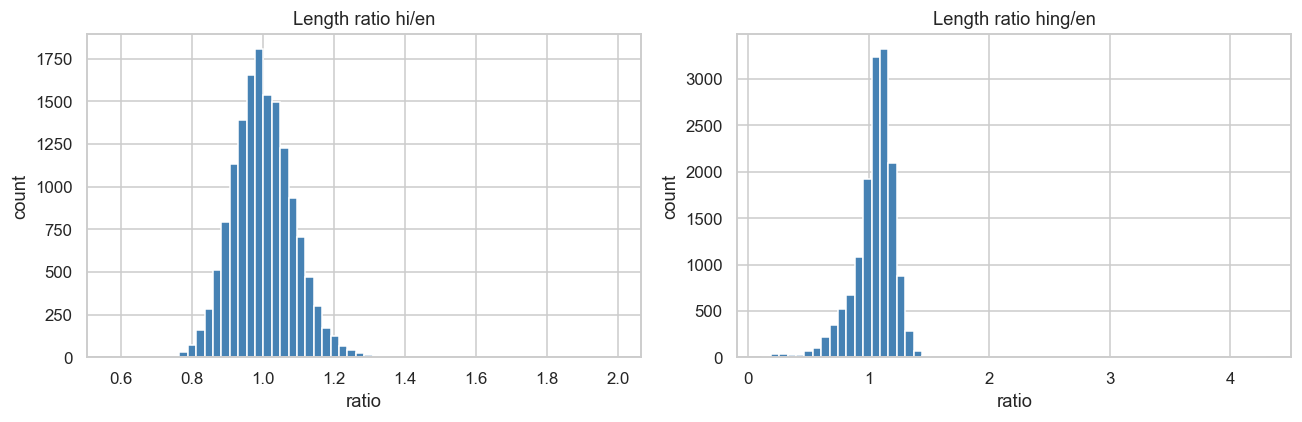

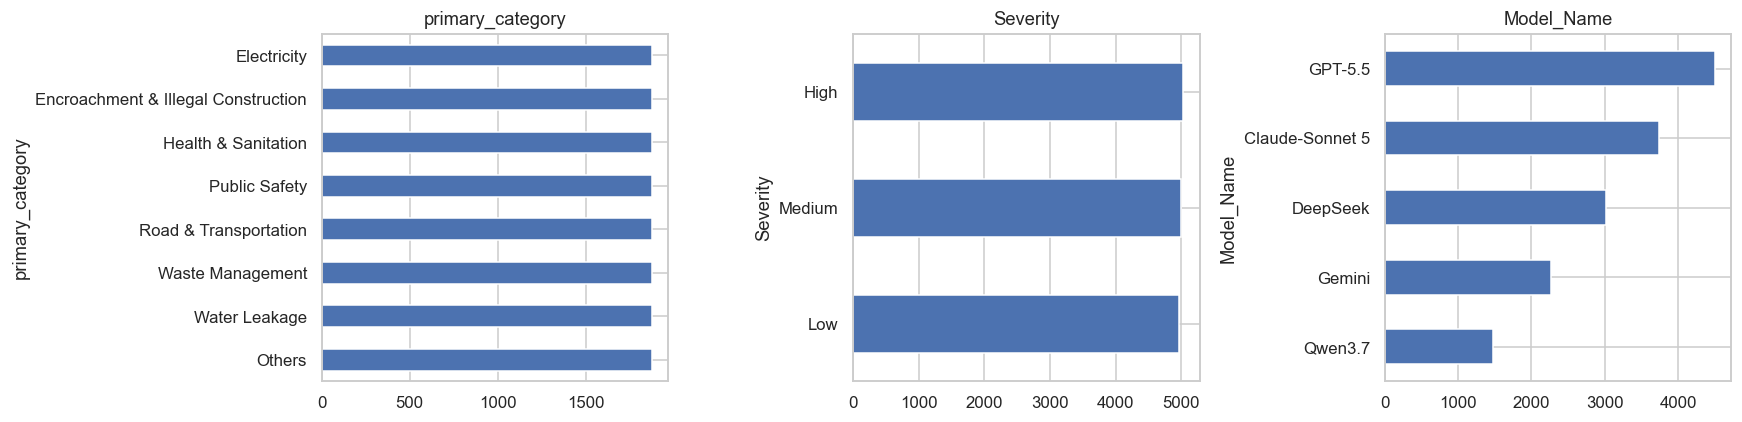

'CivicComp_Synthetic_Validation_Results\\figures\\08_class_balance.png'

In [19]:
# =============================================================================
# 17. VISUALIZATIONS
# =============================================================================
print("\nGenerating figures…")

# 17.1 Quality score violins (both reviewers)
fig, axes = plt.subplots(1, len(SCORE_COLUMNS), figsize=(18, 4), sharey=True)
for ax, col in zip(axes, SCORE_COLUMNS):
    df_long = pd.DataFrame({
        "score": pd.concat([pd.to_numeric(p1[col], errors="coerce"),
                            pd.to_numeric(p2[col], errors="coerce")]),
        "reviewer": ["P1"] * len(p1) + ["P2"] * len(p2),
    }).dropna()
    sns.violinplot(data=df_long, x="reviewer", y="score", ax=ax, cut=0)
    ax.set_title(col); ax.set_xlabel("")
savefig("01_quality_violins")

# 17.2 Reviewer-vs-reviewer scatter (mean per record)
fig, ax = plt.subplots(figsize=(6, 6))
x = pd.to_numeric(p1[SCORE_COLUMNS].mean(axis=1), errors="coerce")
y = pd.to_numeric(p2[SCORE_COLUMNS].mean(axis=1), errors="coerce")
valid = x.notna() & y.notna()
ax.scatter(x[valid], y[valid], alpha=0.3, s=10)
lo, hi = min(x[valid].min(), y[valid].min()), max(x[valid].max(), y[valid].max())
ax.plot([lo, hi], [lo, hi], "r--", lw=1)
rho, p = spearmanr(x[valid], y[valid])
ax.set(xlabel="Person 1 mean score", ylabel="Person 2 mean score",
       title=f"Reviewer agreement  (Spearman ρ={rho:.3f}, p={p:.2g})")
savefig("02_reviewer_scatter")

# 17.3 Language quality boxplot
def long_quality(df, reviewer_label):
    return (
        df[["English_Quality", "Hindi_Quality", "Hinglish_Quality"]]
          .apply(pd.to_numeric, errors="coerce")
          .melt(var_name="Language", value_name="score", ignore_index=True)
          .assign(
              Reviewer=reviewer_label,
              Language=lambda d: d["Language"].str.replace("_Quality", "", regex=False),
          )
    )

lang_long = pd.concat(
    [long_quality(p1, "P1"), long_quality(p2, "P2")],
    ignore_index=True,
).dropna(subset=["score"])

# sanity check — every record should give up to 3 rows per reviewer
expected_max = 3 * (len(p1) + len(p2))
assert len(lang_long) <= expected_max, "lang_long longer than expected"

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=lang_long, x="Language", y="score", hue="Reviewer", ax=ax)
ax.set_title("Language quality distribution")
savefig("03_language_boxplot")

# 17.4 LLM-wise mean quality
fig, ax = plt.subplots(figsize=(9, 4))
llm_pivot = (llm_report.groupby(["LLM", "Dimension"])["Mean"].mean().unstack())
llm_pivot.plot(kind="bar", ax=ax, rot=30)
ax.set_ylabel("Mean score"); ax.set_title("Per-LLM mean quality by dimension")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
savefig("04_llm_quality")

# 17.5 Category × Severity count heatmap
fig, ax = plt.subplots(figsize=(9, 5))
ct = pd.crosstab(sample_df["primary_category"], sample_df["Severity"])
sns.heatmap(ct, annot=True, fmt="d", cmap="YlOrRd", ax=ax)
ax.set_title("Sampled records: primary category × severity")
savefig("05_category_severity_heatmap")

# 17.6 Per-record disagreement heatmap (top 20 records by disagreement count)
if not disagreement_report.empty:
    top_recs = (disagreement_report.groupby("Sy_No").size()
                .sort_values(ascending=False).head(20).index)
    sub = disagreement_report[disagreement_report["Sy_No"].isin(top_recs)]
    hm = (sub.assign(val=1)
             .pivot_table(index="Sy_No", columns="Dimension", values="val",
                          aggfunc="sum", fill_value=0))
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.heatmap(hm, cmap="Reds", annot=True, fmt="d", ax=ax)
    ax.set_title("Top 20 records by reviewer disagreement")
    savefig("06_disagreement_heatmap")
else:
    print("  (skipping disagreement heatmap — no disagreements)")

# 17.7 Length-ratio histograms
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (label, series) in zip(axes, [("hi/en", ratio_df["hi/en"]),
                                       ("hing/en", ratio_df["hing/en"])]):
    s = series.replace([np.inf, -np.inf], np.nan).dropna()
    ax.hist(s[s.between(0, 5)], bins=60, color="steelblue")
    ax.set(title=f"Length ratio {label}", xlabel="ratio", ylabel="count")
savefig("07_length_ratios")

# 17.8 Class balance
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["primary_category", "Severity", "Model_Name"]):
    original_df[col].value_counts().plot(kind="barh", ax=ax)
    ax.set_title(col); ax.invert_yaxis()
savefig("08_class_balance")

In [22]:
# =============================================================================
# 18. FINAL SUMMARY & EXPORT
# =============================================================================
summary = pd.DataFrame({
    "Metric": [
        "Original dataset size", "Manual validation sample size", "Sampling %",
        "Number of reviewers", "Number of quality dimensions",
        "Exact duplicate IDs", "Extra duplicate English rows",
        "Near-duplicate pairs (≥0.90)", "Reviewer disagreement entries",
        "ICC dimensions computed", "Figures generated",
    ],
    "Value": [
        len(original_df), len(p1),
        round(len(p1) / len(original_df) * 100, 2),
        2, len(SCORE_COLUMNS),
        len(dup_ids), len(dup_en),
        len(near_duplicate_report), len(disagreement_report),
        len(os.listdir(FIG_DIR)),
    ],
})

sheets = {
    "Overall_Summary":        summary,
    "Dataset_Integrity":      integrity,
    "Inter_Rater_Agreement":  agreement_report,
    "Human_Quality":          quality_report,
    "Language_Quality":       language_report,
    "Label_Corrections":      label_report,
    "LLM_Wise_Quality":       llm_report,
    "Category_Wise_Quality":  category_report,
    "Severity_Wise_Quality":  severity_report,
    "Statistical_Analysis":   statistics_report,
    "Exact_Duplicates":       exact_duplicate_report,
    "Near_Duplicates":        near_duplicate_report,
    "Lexical_Diversity":      diversity_report,
    "Template_Leakage":       template_report,
    "Length_Ratios":          ratio_stats.reset_index(),
    "Vocab_Overlap":          overlap_table,
}


with pd.ExcelWriter(OUTPUT_EXCEL, engine="openpyxl") as w:
    for name, df in sheets.items():
        df.to_excel(w, name[:31], index=False)   # Excel sheet name limit

print("\n" + "=" * 70)
print("✅ VALIDATION REPORT GENERATED")
print("=" * 70)
print(f"Workbook     : {OUTPUT_EXCEL}")
print(f"CSV artifacts: {OUTPUT_DIR}")
print(f"Figures      : {FIG_DIR}  ({len(os.listdir(FIG_DIR))} files)")

ValueError: All arrays must be of the same length

Per-record similarity table: (15000, 3)
            EN↔HI     EN↔HING     HI↔HING
count  15000.0000  15000.0000  15000.0000
mean       0.0026      0.2063      0.0066
std        0.0114      0.1621      0.0204
min        0.0000      0.0000      0.0000
25%        0.0000      0.0897      0.0000
50%        0.0000      0.1568      0.0000
75%        0.0000      0.2777      0.0016
max        0.1786      0.9623      1.0000

CROSS-LANGUAGE COSINE SIMILARITY
   Pair     N   Mean     SD  Median     Q1     Q3  Min    Max  Mean_CI_Low  Mean_CI_High
  EN↔HI 15000 0.0026 0.0114  0.0000 0.0000 0.0000  0.0 0.1786       0.0024        0.0028
EN↔HING 15000 0.2063 0.1621  0.1568 0.0897 0.2777  0.0 0.9623       0.2037        0.2088
HI↔HING 15000 0.0066 0.0204  0.0000 0.0000 0.0016  0.0 1.0000       0.0063        0.0069

Wilcoxon EN↔HI vs EN↔HING: W=25455.0, p=0, N=15000

The mean cosine similarity was 0.003 (SD: 0.011) for English–Hindi pairs and 0.206 (SD: 0.162) for English–Hinglish pairs.


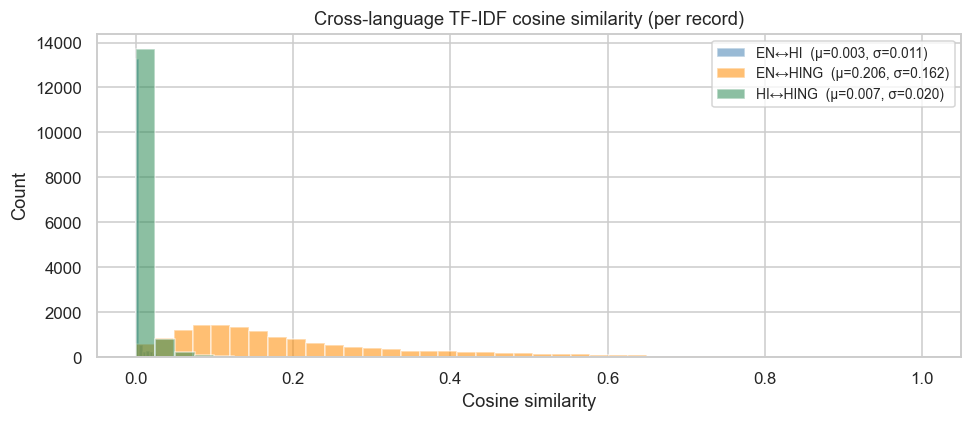


Saved: CivicComp_Synthetic_Validation_Results\Per_Record_Cosine_Similarity.csv


In [23]:
# =============================================================================
# 16g. CROSS-LANGUAGE COSINE SIMILARITY  (per-record, paired)
#      EN↔HI  vs  EN↔HING  (and HI↔HING for completeness)
# =============================================================================
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity as _cos_sim
from scipy.stats import wilcoxon as _wilcoxon

def pair_cosine_similarity(df, col_a, col_b,
                           word_ngrams=(1, 2),
                           char_ngrams=(3, 5),
                           min_df=1):
    """
    Return a Series of per-record cosine similarities between two text columns.
    Uses word-level + char-level TF-IDF so that translation length differences
    and spelling variants don't artificially deflate similarity.
    Rows where either side is blank/NaN are excluded (index preserved).
    """
    a = df[col_a].fillna("").astype(str).str.lower().str.strip()
    b = df[col_b].fillna("").astype(str).str.lower().str.strip()

    valid = a.ne("") & b.ne("")
    a, b = a[valid], b[valid]

    # Fit on the concatenation so both sides live in the same vector space
    vec = TfidfVectorizer(
        analyzer="word",
        ngram_range=word_ngrams,
        min_df=min_df,
        sublinear_tf=True,
        strip_accents="unicode",
    )
    A = vec.fit_transform(pd.concat([a, b], ignore_index=True))
    n = len(a)
    word_sims = np.array([
        _cos_sim(A[i], A[n + i])[0, 0] for i in range(n)
    ])

    # Char-level TF-IDF (catches morphological variants / Hinglish spelling)
    vec_c = TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=char_ngrams,
        min_df=min_df,
        sublinear_tf=True,
        strip_accents="unicode",
    )
    Ac = vec_c.fit_transform(pd.concat([a, b], ignore_index=True))
    char_sims = np.array([
        _cos_sim(Ac[i], Ac[n + i])[0, 0] for i in range(n)
    ])

    # Average the two views (robust to short/long complaints)
    combined = (word_sims + char_sims) / 2.0
    return pd.Series(combined, index=a.index, name=f"cos_{col_a}__{col_b}")


# ---- compute per-pair similarities -----------------------------------------
PAIRS = [
    ("Text_en", "Text_hi",       "EN↔HI"),
    ("Text_en", "Text_hinglish", "EN↔HING"),
    ("Text_hi", "Text_hinglish", "HI↔HING"),
]

sim_df = pd.DataFrame(index=original_df.index)
for a, b, label in PAIRS:
    sim_df[label] = pair_cosine_similarity(original_df, a, b)
print("Per-record similarity table:", sim_df.shape)
print(sim_df.describe().round(4).to_string())


def _bootstrap_ci(vals, n_boot=5000, seed=RANDOM_STATE):
    vals = np.asarray(vals, dtype=float)
    vals = vals[np.isfinite(vals)]
    if vals.size == 0:
        return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    means = np.array([rng.choice(vals, size=vals.size, replace=True).mean()
                      for _ in range(n_boot)])
    return (float(np.percentile(means, 2.5)),
            float(np.percentile(means, 97.5)))


# ---- summary table ---------------------------------------------------------
rows = []
for label in sim_df.columns:
    s = sim_df[label].dropna()
    lo, hi = _bootstrap_ci(s.values)
    rows.append({
        "Pair": label,
        "N": int(s.size),
        "Mean": round(s.mean(), 4),
        "SD": round(s.std(), 4),
        "Median": round(s.median(), 4),
        "Q1": round(s.quantile(0.25), 4),
        "Q3": round(s.quantile(0.75), 4),
        "Min": round(s.min(), 4),
        "Max": round(s.max(), 4),
        "Mean_CI_Low": round(lo, 4),
        "Mean_CI_High": round(hi, 4),
    })
cosine_summary = pd.DataFrame(rows)
print("\nCROSS-LANGUAGE COSINE SIMILARITY")
print(cosine_summary.to_string(index=False))

# ---- paired test: EN↔HI vs EN↔HING ----------------------------------------
paired = sim_df[["EN↔HI", "EN↔HING"]].dropna()
if len(paired) > 0 and not np.allclose(paired.iloc[:, 0], paired.iloc[:, 1]):
    W, p = _wilcoxon(paired["EN↔HI"], paired["EN↔HING"],
                     alternative="two-sided")
else:
    W, p = np.nan, 1.0
print(f"\nWilcoxon EN↔HI vs EN↔HING: W={W:.1f}, p={p:.4g}, "
      f"N={len(paired)}")

# ---- formatted sentence ----------------------------------------------------
en_hi_mean  = cosine_summary.loc[cosine_summary.Pair == "EN↔HI",    "Mean"].iloc[0]
en_hi_sd    = cosine_summary.loc[cosine_summary.Pair == "EN↔HI",    "SD"].iloc[0]
en_hing_mean = cosine_summary.loc[cosine_summary.Pair == "EN↔HING", "Mean"].iloc[0]
en_hing_sd   = cosine_summary.loc[cosine_summary.Pair == "EN↔HING", "SD"].iloc[0]

SENTENCE = (
    f"The mean cosine similarity was {en_hi_mean:.3f} (SD: {en_hi_sd:.3f}) "
    f"for English–Hindi pairs and {en_hing_mean:.3f} (SD: {en_hing_sd:.3f}) "
    f"for English–Hinglish pairs."
)
print("\n" + SENTENCE)

# ---- figure ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4))
for label, color in [("EN↔HI", "steelblue"),
                     ("EN↔HING", "darkorange"),
                     ("HI↔HING", "seagreen")]:
    s = sim_df[label].dropna()
    ax.hist(s, bins=40, alpha=0.55, color=color,
            label=f"{label}  (μ={s.mean():.3f}, σ={s.std():.3f})")
ax.set_xlabel("Cosine similarity"); ax.set_ylabel("Count")
ax.set_title("Cross-language TF-IDF cosine similarity (per record)")
ax.legend(fontsize=9)
savefig("09_cross_language_cosine")

# ---- persist as artifact --------------------------------------------------
sim_df.to_csv(os.path.join(OUTPUT_DIR, "Per_Record_Cosine_Similarity.csv"),
              index=False)
cosine_summary.to_csv(os.path.join(OUTPUT_DIR,
                                   "Cross_Language_Cosine_Summary.csv"),
                     index=False)
print("\nSaved:", os.path.join(OUTPUT_DIR, "Per_Record_Cosine_Similarity.csv"))